# MINERvA Z-Expansion Axial Form Factor Correction Fake Data Study -- Containment Split

Fake data = nominal MC reweighted by `MINERvAZExpFitCorrection_weight`, the MINERvA-informed Z-expansion axial form factor correction dial exported as a single flat weight (not a full multisim spline) by Kiyoung's medulla fork (`to_gundam.cc`: https://github.com/kyjung123/medulla/blob/f62fefff00b3c2e80fc9a623afa9f7f63a6d8305/systematics/src/to_gundam.cc#L218-L227 and #L331-L337). Unlike `FakeData_QE_dpTShape`/`FakeData_QE_ProtonP`, this weight comes directly from a GENIEReWeight computation already baked into the GUNDAM input tree (once regenerated) rather than a hand-derived binned table -- see `Configs_DataSetList/dataSetListConfig_FakeData_MINERvA.yaml` for the full derivation notes.

**Built containment-split (contained/exiting simultaneous fit) only** -- no combined-sample variant for this study.

**PREREQUISITE (not yet satisfied as of this notebook's creation):** `MINERvAZExpFitCorrection_weight` does not yet exist in the GUNDAM input file. It requires pulling Kiyoung's updated `to_gundam.cc` into the systematics-tree generation step and regenerating the file before the Fitter/ToyGenerator/CalcXSec steps referenced here can produce anything to plot.

**Binning:** truth binning is the medulla-optimized combined dpT binning (`binning_true_dpT.txt`, 6 finite + 1 overflow = 7 bins). Reco binning is per-channel: contained samples use `binning_reco_dpT_contained.txt` (20 finite + 1 overflow = 21 rows), exiting samples use `binning_reco_dpT_exiting.txt` (10 finite + 1 overflow = 11 rows).

**`cov_bin_range` -- carried over from the QE_dpTShape_Containment closure test, NOT yet re-verified for this run.** Block boundaries in the full 64x64 matrix are at 0, 21, 32, 53, 64 (with-overflow widths); each slice used for chi2 stops one row short of its block boundary to match the category histograms: selection_contained (0,20), selection_exiting (21,31), sideband_contained (32,56), sideband_exiting (57,81). Since `enablePca: true` reduces parameters based on the actual response matrix, and this reweighting could shift bin population differently than the QE_dpTShape run, re-check these boundaries against this run's own `covarianceMatrix_TH2D` axis labels before trusting the per-sample chi2 breakdown.


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Selection - Contained

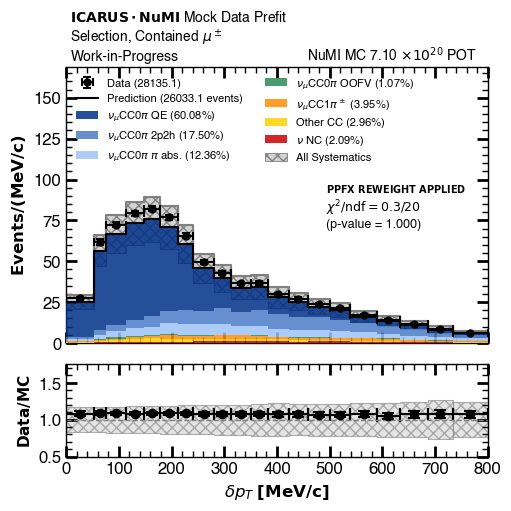

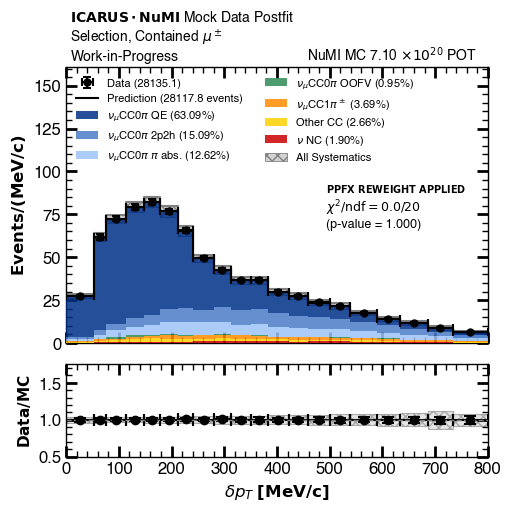

In [2]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/prefit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # block boundaries carried over from the QE_Containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Prefits', save_name='prefit_dpT_selection_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/postfit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Postfits', save_name='postfit_dpT_selection_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Selection - Exiting

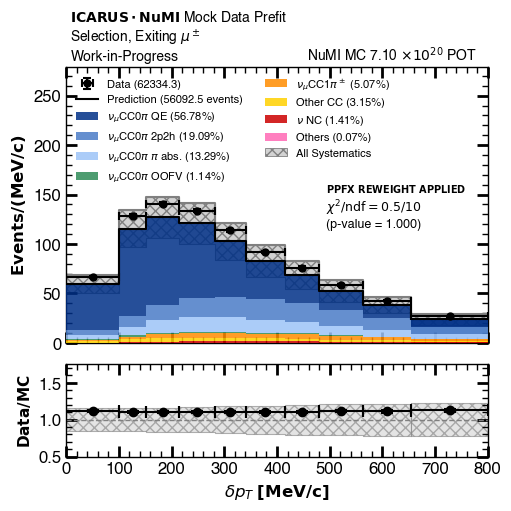

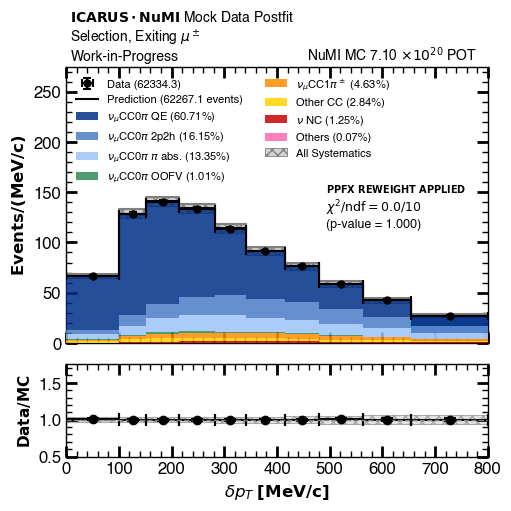

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/prefit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # block boundaries carried over from the QE_Containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Prefits', save_name='prefit_dpT_selection_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/postfit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Postfits', save_name='postfit_dpT_selection_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Sideband - Contained

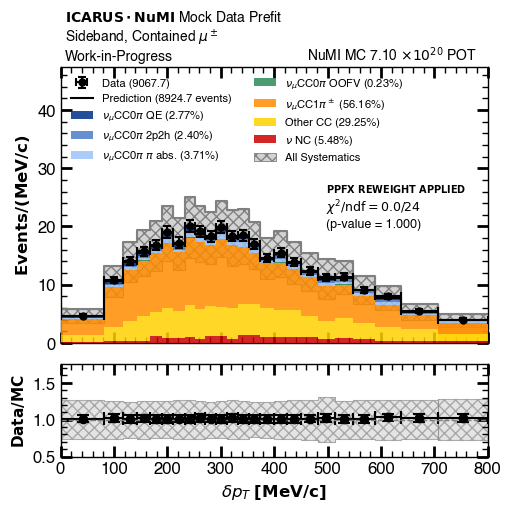

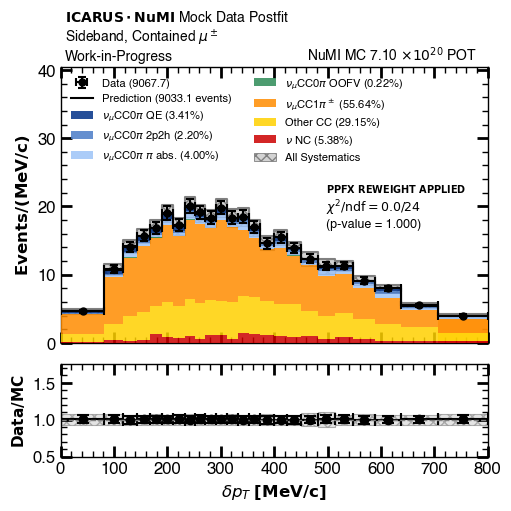

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/prefit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # block boundaries carried over from the QE_Containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Prefits', save_name='prefit_dpT_sideband_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/postfit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Postfits', save_name='postfit_dpT_sideband_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Sideband - Exiting

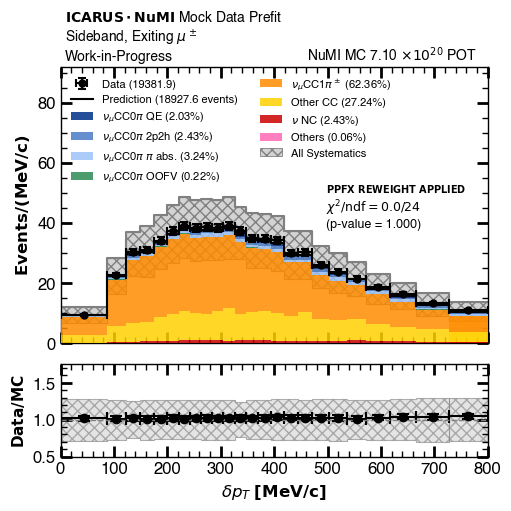

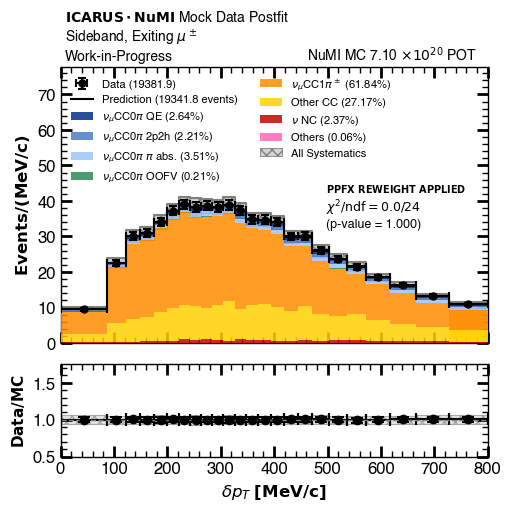

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/prefit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # block boundaries carried over from the QE_Containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Prefits', save_name='prefit_dpT_sideband_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/postfit_fakeData_MINERvA_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_MINERvA_Containment/Postfits', save_name='postfit_dpT_sideband_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Cross-Section Extraction

From `fakeData_MINERvA_XSec_dpT_containment.root`. Truth-level, 7 truth bins -- unchanged by the reco-level containment split.


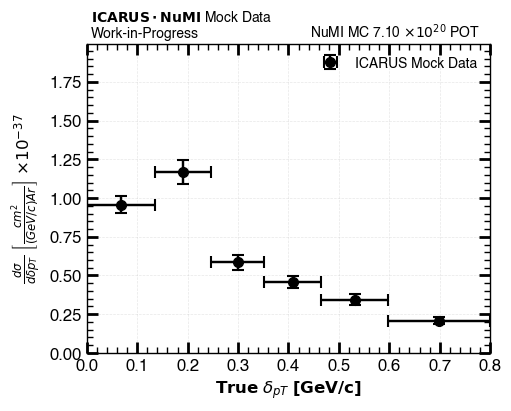

In [6]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_XSec_dpT_containment.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_dpT_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel=r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-37}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Mock Data",
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/dpT/FakeData_MINERvA_Containment/XSection', 'dpT_XS')


In [7]:
# Scale extracted
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

# Overlay 1: nominal GENIE vs extracted
fig_xs, ax_xs, xsec_nominal, chi2_nominal = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i',
    color='steelblue',
    reweight_mode=None,
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
    nominal_label='AR23_20i',
    add_ratio=True,
    draw_extracted_ratio=False,
)



GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.758637e-01
  0.1350 – 0.2460           1.059684e+00
  0.2460 – 0.3520           5.451330e-01
  0.3520 – 0.4650           4.246163e-01
  0.4650 – 0.5980           3.148177e-01
  0.5980 – 0.8000           1.866928e-01

χ² / Ndof = 7.0 / 6 = 1.165
p-value = 0.322


### MINERvA-corrected "expected" GENIE cross section

**Updated (this pass):** this used to require a manual step -- run a ROOT
command on GPVM by hand and paste its `ratios = [...]` output into the cell
below. That workflow is retired.

The MINERvA-corrected cross section is now read directly from
`expected_fakedata_xsec.txt` (written by
`Notebooks/export_expected_fakedata_xsec.py`), which computes it the same
way `signal_xs_studies.ipynb` Part 4 does: directly from the
`events/full/signal` tree, using the exact fake-data weight formula in
`dataSetListConfig_FakeData_MINERvA.yaml`:

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 1.0 & \text{MINERvAZExpFitCorrection\_weight} < 0 \\ \text{MINERvAZExpFitCorrection\_weight} & \text{otherwise}\end{cases}$$

This also fixes a bug in the retired ROOT snippet: it binned
`true_dpT_lp_genie` on `{0, 80, 160, 240, 320, 520, 800}` MeV, not the
analysis binning `{0, 135, 246, 352, 465, 598, 800}` MeV used everywhere
else in this notebook (`binning_true_dpT.txt`) -- the same bin-edge
mismatch documented in `signal_xs_studies.ipynb` Part 3. `overlay_genie_nuisance_xsec`
now checks the requested `bin_edges` against the edges stored in the txt
file and raises an error on any mismatch, so this class of bug can no
longer pass silently.

`overlay_genie_nuisance_xsec` reads this value directly via its new
`expected_xsec_file`/`expected_xsec_study` arguments (see
`plot_GENIE_NUISANCE.py`), instead of the `reweight_mode` path Overlay 1
uses -- MINERvA has no native `reweight_mode` support because it is a
GENIEReWeight dial applied to the GUNDAM input tree itself (see `Configs_DataSetList/dataSetListConfig_FakeData_MINERvA.yaml`),
not a NEUT/GENIE nuisflat-level reweight, and its own convention for
interaction mode differs from the nuisflat tree's `Mode` branch.



Expected fake-data Cross-Section (MINERvA, from expected_fakedata_xsec.txt)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           9.862420e-01
  0.1350 – 0.2460           1.171892e+00
  0.2460 – 0.3520           5.772830e-01
  0.3520 – 0.4650           4.459750e-01
  0.4650 – 0.5980           3.362300e-01
  0.5980 – 0.8000           2.064710e-01

χ² / Ndof = 0.4 / 6 = 0.071
p-value = 0.999


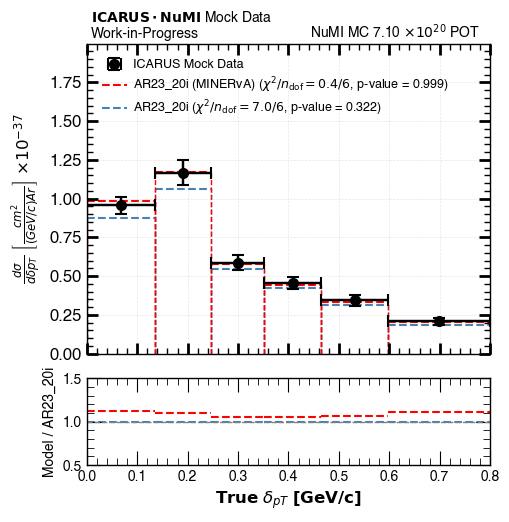

In [8]:
fig_xs, ax_xs, xsec_minerva, chi2_minerva_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    expected_xsec_file='expected_fakedata_xsec.txt',
    expected_xsec_study='MINERvA',
    label='AR23_20i (MINERvA)',
    color='red',
    nominal_label='AR23_20i',
    add_ratio=True,
    draw_extracted_ratio=False,
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
)

save_fig(fig_xs, r'../Plots/dpT/FakeData_MINERvA_Containment/XSection', 'dpT_XS_wGENIE')
display(fig_xs)


## Template Parameter Post-fit Values

One set of 7 template parameters, shared across all four samples -- not split by containment.

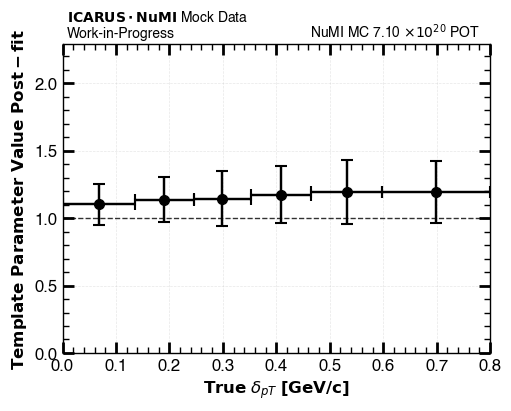

In [9]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dpT_lp_genie/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT'
)
save_fig(fig_template, r'../Plots/dpT/FakeData_MINERvA_Containment/TemplateParameters', 'dpT')

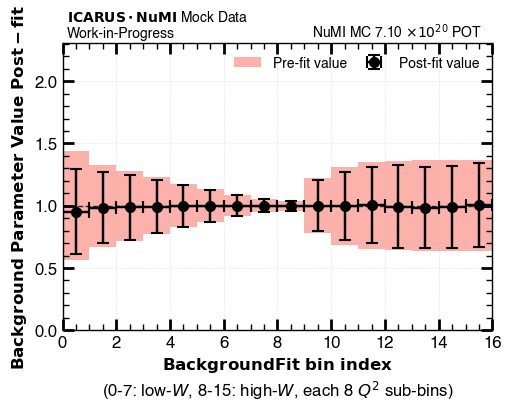

In [10]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dpT/FakeData_MINERvA_Containment/BackgroundFitParameters', 'dpT_w')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


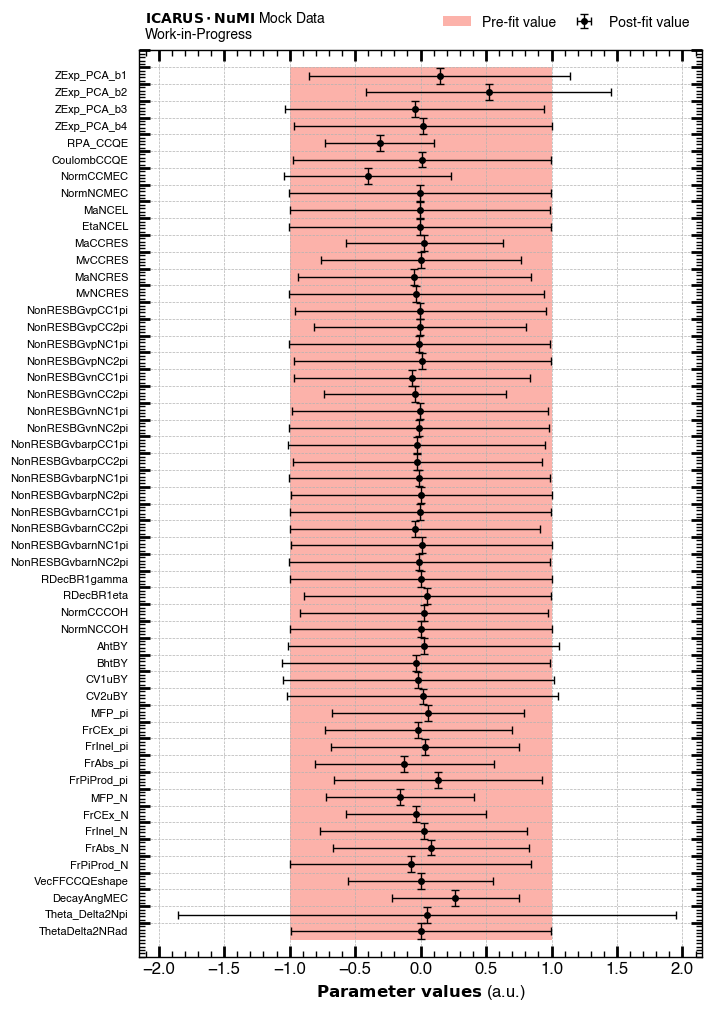

In [11]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_InteractionModel')

Number of parameters: 27


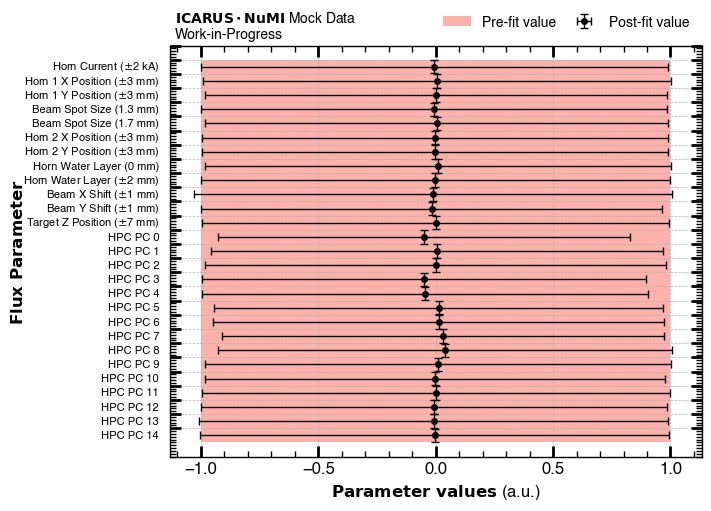

In [12]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_Flux')

Number of parameters: 9


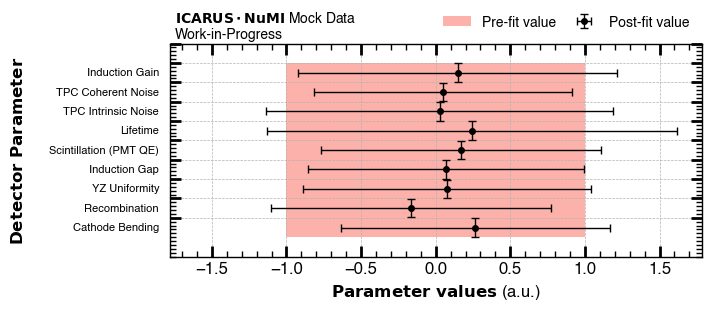

In [13]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_Detector')

Number of parameters: 5


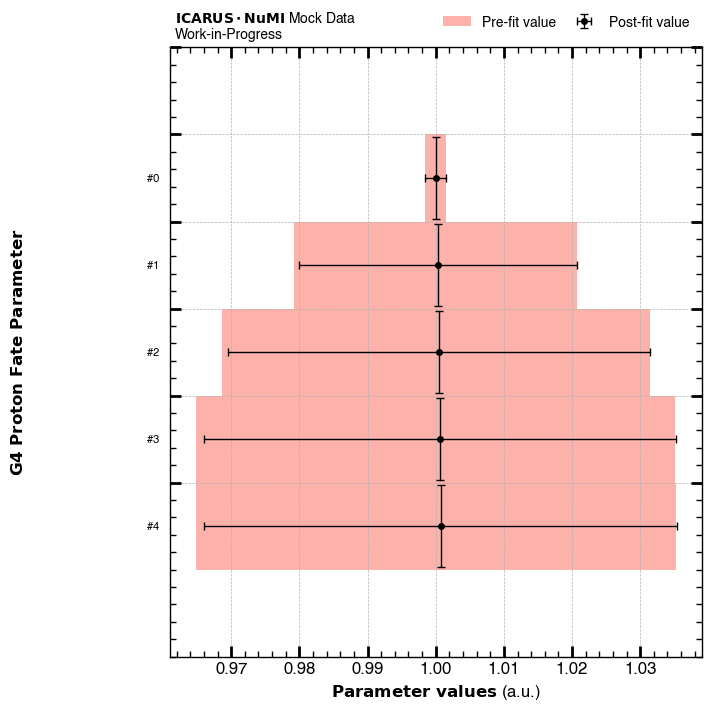

In [14]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_G4_Proton')

Number of parameters: 3


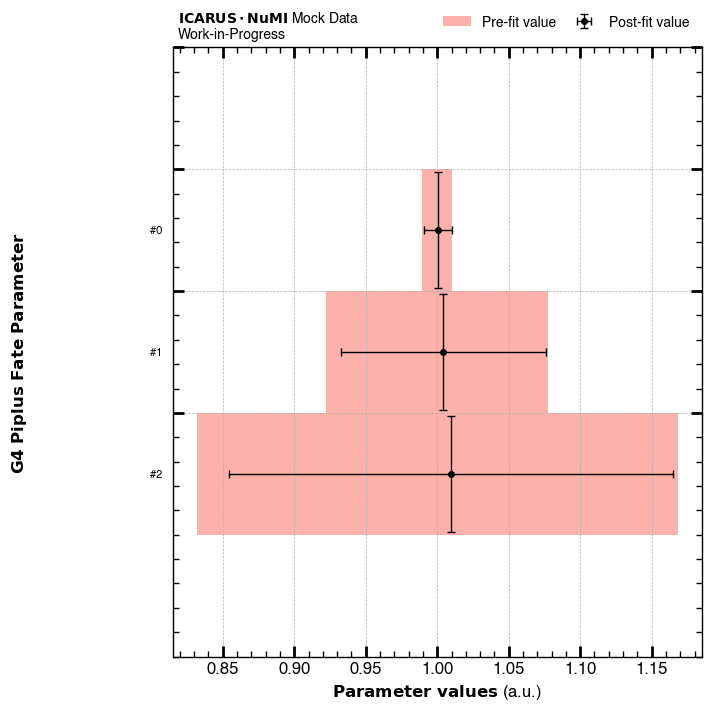

In [15]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_G4_Piplus')

Number of parameters: 3


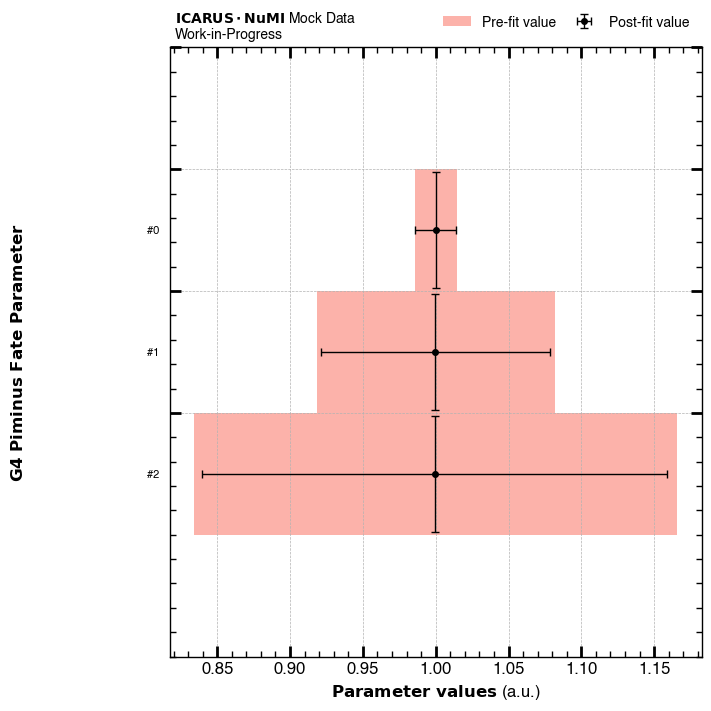

In [16]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_MINERvA_Containment/NuisanceParameters', 'dpT_G4_Piminus')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


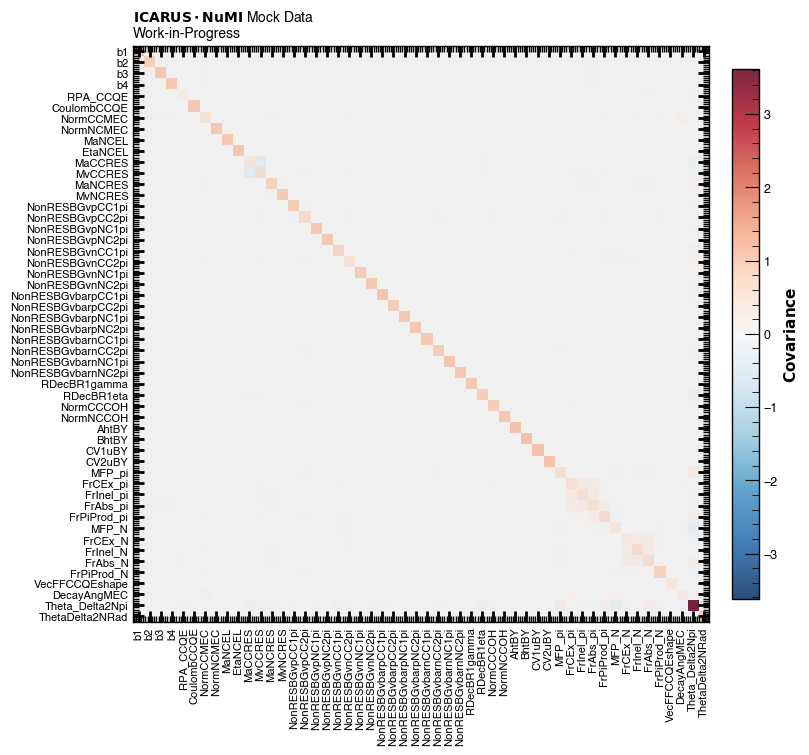

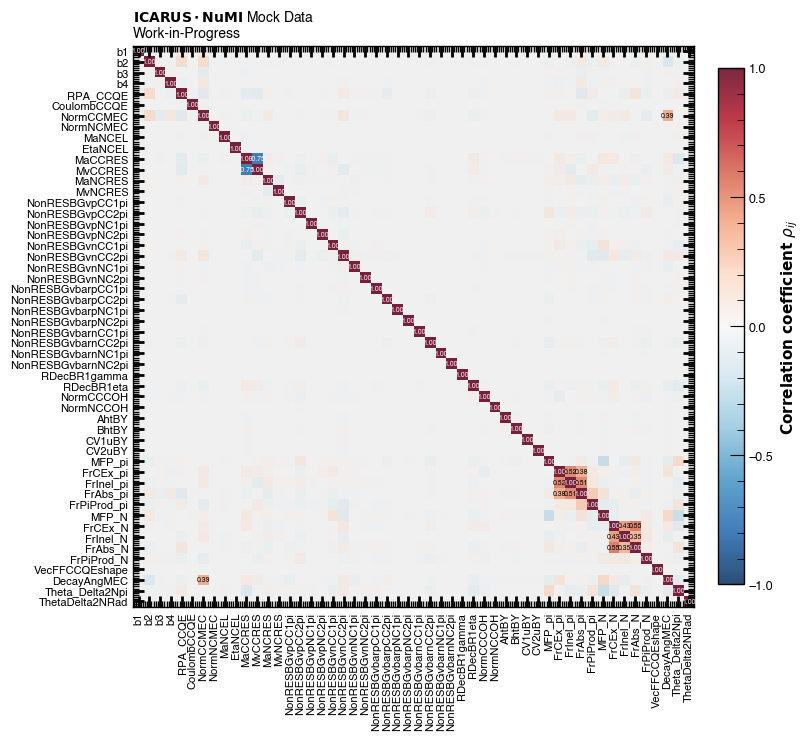

In [17]:
BASE_ = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    figsize=(8, 20),
    cov_path  = f"{BASE_}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE_}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


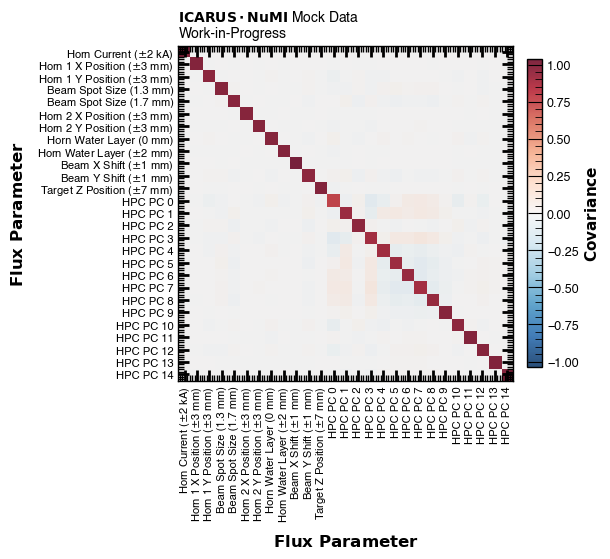

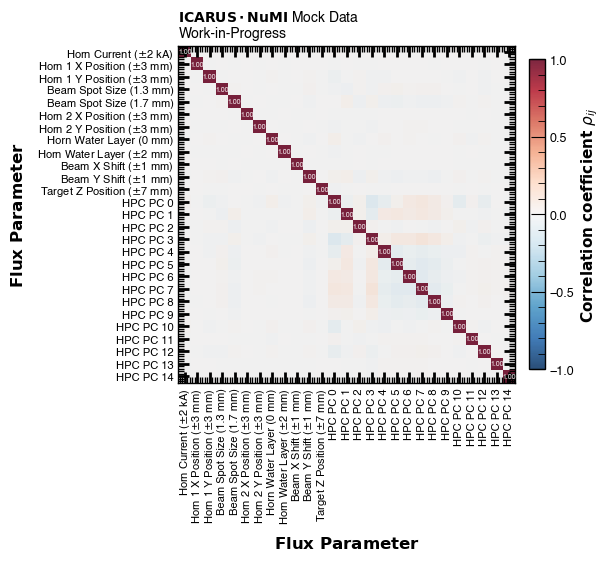

In [18]:
BASE_ = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE_}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE_}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


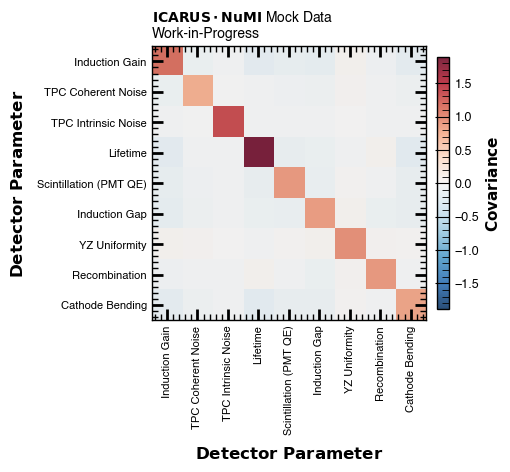

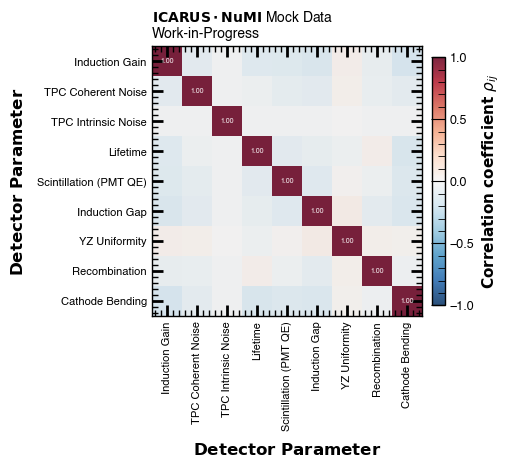

In [19]:
BASE_ = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_MINERvA_Containment/fakeData_MINERvA_dpT_containment.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE_}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE_}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_MINERvA_Containment/Postfits', 'detector_param_correlation')